# 2. 分支结构

## 2.1 并行节点

In [15]:
from langgraph.graph import StateGraph, START, END
from langchain_deepseek import ChatDeepSeek
from langchain.messages import HumanMessage
from typing import TypedDict, Literal
from rich import print as rprint

from dotenv import load_dotenv
load_dotenv(override=True)


model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    poem: str
    joke: str
    content_type: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(content=f"请写一首关于{state['topic']}的七言绝句。")]).content
    return {"poem": poem}

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(content=f"请写一个关于{state['topic']}的笑话。")]).content
    return {"joke": joke}



{
    'topic': '小猫',
    'poem': 
'《小猫》\n绒团初醒步轻挪，扑蝶攀枝趣事多。\n一跃膝头呼噜响，娇憨最是惹人呵。\n\n注：我的创作思路是抓住小猫的灵动与
娇憨之态。首句“绒团初醒”写其睡眼惺忪的可爱模样，“步轻挪”表现其优雅步态。次句通过扑蝶攀枝的典型动作展现活泼天性。第
三句转写与人亲昵的呼噜声，结句“娇憨”总括其态，“惹人呵”则自然流露出怜爱之情。',
    'joke': 
'一只小猫走进了一家酒吧，坐到吧台前。\n\n酒保看了看它，说：“对不起，我们这里不招待猫。”\n\n小猫淡定地掏出一张百元大
钞拍在桌上：“给我来一杯牛奶。”\n\n酒保愣了一下，心想反正有钱赚，就给它倒了一碗牛奶。小猫喝完，又拍了一张百元大钞：“
再来一碗。”\n\n就这样，小猫一连喝了五碗牛奶，每碗都付了一百块。酒保终于忍不住了，问：“小家伙，你哪来这么多钱？”\n\n
小猫舔了舔爪子，慢悠悠地说：“我主人是位作家，他每天坐在电脑前敲键盘，我就趴在旁边看。有一天他出门了，我踩了几下键盘
，他就成畅销书作家了。”\n\n酒保惊讶地问：“你写了什么？”\n\n小猫耸耸肩：“我也不知道，好像是本《如何训练你的铲屎官》
。”'
}

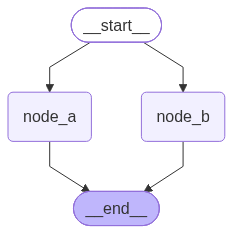

In [16]:
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge(START, "node_b")
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫"})
rprint(result)

from IPython.display import display
display(graph)

上述案例中，`node_a` 和 `node_b` 都由 START 触发。图运行时，二者会在同一个超步中被调度，它们各自读取当前状态并独立执行。

需要注意的是：

- 这里的“并行”主要指调度语义上的并行；两个节点之间没有先后依赖；
- 它们的输出会在当前超步执行完成后统一合并到状态中；
- 如果两个节点写入同一个状态字段，则该字段通常需要配置合适的 `Reducer`，否则可能出现状态更新冲突，抛出 `InvalidUpdateError` 异常

{
    'topic': '小猫',
    'poem': 
'《咏小猫》\n绒团初醒弄娇柔，扑蝶攀花兴未休。\n忽见镜中疑二己，弓身炸尾怯还羞。\n\n注：我的创作思路是抓住小猫活泼又
天真的特性。首句以“绒团”喻其柔软可爱，“弄娇柔”拟人化其姿态。次句通过扑蝶攀花展现其顽皮。后两句聚焦照镜子的瞬间，用“
弓身炸尾”的生动细节，刻画小猫面对镜中影像时既好奇又畏惧的复杂心理，形成诗意转折，饶有趣味。',
    'joke': 
'小猫问妈妈：“妈妈，为什么我们走路没有声音？”\n\n猫妈妈说：“因为我们脚上有肉垫啊。”\n\n小猫又问：“那为什么我们要有
肉垫呢？”\n\n猫妈妈说：“这样抓老鼠的时候才不会被发现呀。”\n\n小猫想了想，高兴地说：“那我以后走路也要静悄悄的！”\n\n
猫妈妈欣慰地点点头。\n\n第二天，猫妈妈发现小猫蹲在鱼缸旁边，一动不动，表情特别严肃。\n\n猫妈妈问：“你在干嘛？”\n\n
小猫小声说：“嘘——别出声，我在等鱼睡觉，然后偷偷抓它。”\n\n猫妈妈叹了口气：“孩子，鱼……不睡觉的。”\n\n小猫愣了一下，
然后特别认真地回答：\n\n“那它总得闭眼吧？”'
}

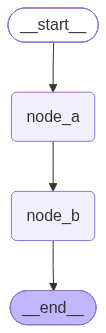

In [17]:
builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"topic": "小猫"})
rprint(result)

from IPython.display import display
display(graph)

## 2.2 条件分支

`StateGraph` 提供了 `add_conditional_edges` 方法，用于从某个上游节点出发，根据运行时状态选择下游节点。

方法签名如下：
```python
def add_conditional_edges(
    self,
    source: str,
    path: Callable[..., Hashable | Sequence[Hashable]]
    | Callable[..., Awaitable[Hashable | Sequence[Hashable]]]
    | Runnable[Any, Hashable | Sequence[Hashable]],
    path_map: dict[Hashable, str] | list[str] | None = None,
) -> Self:
    ...
```
不考虑 self，核心参数有三个：
- `source`：条件分支的起始节点；
- `path`：路由规则，是一个可执行对象，通常是函数
- `path_map`：路由规则的返回值到真实节点名之间的映射关系。

其中，`path` 的返回值表示跳转的目标节点，可以是：
- 字符串或特殊对象 `END` 表示的单个目标；
- 字符串或特殊对象 `END` 表示的多个目标组成的序列；

`path_map`
- 可以省略，即取默认值 None，此时 path 返回值中出现的字符串必须是合法的节点名称。
- 可以是字典，维护 path 返回值和真实节点的映射。
- 也可以是列表，如下
```python
path_map=["node_a", "node_b", "node_c"]
# 相当于
path_map={
    "node_a": "node_a",
    "node_b": "node_b",
    "node_c": "node_c",
}
```
此时也要求 path 返回值中出现的字符串必须是合法的节点名称。

{
    'topic': '小猫',
    'joke': 
'有一天，小猫问妈妈：“妈妈，为什么我们走路总是静悄悄的？”\n\n猫妈妈说：“因为我们是猫啊，走路当然要轻。”\n\n小猫又问
：“那为什么我们吃东西也静悄悄的？”\n\n猫妈妈说：“因为要优雅。”\n\n小猫想了想，又问：“那为什么我们上厕所还要刨坑埋起
来？”\n\n猫妈妈叹了口气说：“因为不想让狗发现啊。”\n\n小猫恍然大悟：“哦！所以狗每次看到我们就狂叫，是因为它们找不到
我们的厕所，急的吗？”',
    'content_type': ''
}

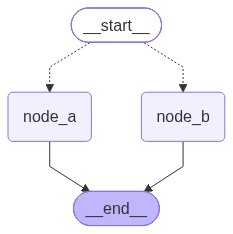

In [20]:
def route(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "node_a"
    else:
        return "node_b"


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_conditional_edges(
    source=START,
    path=route
)

graph = builder.compile()
result = graph.invoke({"topic": "小猫", "content_type": ""})
# result = graph.invoke({"topic": "小猫", "content_type": "诗"})
rprint(result)

from IPython.display import display
display(graph)